In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import pearsonr, spearmanr

# 1. Resolve paths & load processed GSE236932 artifacts
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Scripts" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "Processed"

print(PROJECT_ROOT)
print(PROCESSED_DIR)

X_circ_logcpm = pd.read_csv(PROCESSED_DIR / "GSE236932_circRNA_log2cpm.csv", index_col=0)
scores_df = pd.read_csv(PROCESSED_DIR / "GSE236932_target_scores.csv", index_col=0)

with open(PROCESSED_DIR / "signatures.json") as f:
    signatures = json.load(f)

# Align sample order
sample_cols = scores_df.index.tolist()
X_circ_logcpm = X_circ_logcpm[sample_cols]

# 2. Filter for consistently expressed circRNAs (log2CPM >= 1.0 in at least 30% of samples = ~19 samples)
expressed_mask = (X_circ_logcpm >= 1.0).sum(axis=1) >= 19
valid_circs = X_circ_logcpm.loc[expressed_mask]
print(f"Candidate circRNA pool after expression filtering: {valid_circs.shape[0]} circRNAs")

X = valid_circs.T  # Shape: (63 samples, N circRNAs)
target_sig = "Hypoxia_Buffa"
y = scores_df[target_sig].values
groups = scores_df['Group'].values

# 3. 5-Fold Stratified Cross-Validation (maintains BT/BP/BN proportions in every fold)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_preds = np.zeros_like(y)
coef_matrix = np.zeros((5, X.shape[1]))

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, groups)):
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('select', SelectKBest(score_func=f_regression, k=50)),
        ('model', ElasticNetCV(
            l1_ratio=[0.3, 0.5, 0.7, 0.9],
            cv=5,
            max_iter=10000,
            random_state=42
        ))
    ])
    
    pipe.fit(X.iloc[train_idx], y[train_idx])
    y_preds[test_idx] = pipe.predict(X.iloc[test_idx])
    
    selected_mask = pipe.named_steps['select'].get_support()
    coef_matrix[fold_idx, selected_mask] = pipe.named_steps['model'].coef_

# 4. Evaluate Out-of-Fold Generalization
r2 = r2_score(y, y_preds)
r_p, p_p = pearsonr(y, y_preds)
r_s, p_s = spearmanr(y, y_preds)

print(f"\n=== 5-Fold Out-of-Fold Performance ({target_sig}, n=63) ===")
print(f"Out-of-Fold R^2 : {r2:.3f}")
print(f"Pearson r       : {r_p:.3f} (p = {p_p:.4e})")
print(f"Spearman rho    : {r_s:.3f} (p = {p_s:.4e})")
print(f"MAE             : {mean_absolute_error(y, y_preds):.3f}")

# 5. Rank top candidate circRNA drivers by Selection Frequency across the 5 folds
coef_df = pd.DataFrame(coef_matrix, columns=X.columns)
summary_circ = pd.DataFrame({
    'Selection_Freq': (coef_df != 0).mean(axis=0),  # 1.0 = selected in all 5 folds
    'Mean_Coef': coef_df.mean(axis=0),
    'Abs_Mean_Coef': coef_df.mean(axis=0).abs()
})
summary_circ = summary_circ[summary_circ['Selection_Freq'] > 0].sort_values(
    by=['Selection_Freq', 'Abs_Mean_Coef'], ascending=False
)

print("\n=== Top 15 Candidate circRNA Drivers of Hypoxia in Bladder Cancer ===")
print(summary_circ.head(15).round(4))

# Save predictions and ranked drivers
eval_df = pd.DataFrame({
    'Group': groups,
    'Actual_Hypoxia': y,
    'Predicted_Hypoxia': y_preds
}, index=sample_cols)
eval_df.to_csv(PROCESSED_DIR / f"GSE236932_predictions_{target_sig}.csv")
summary_circ.to_csv(PROCESSED_DIR / f"GSE236932_top_drivers_{target_sig}.csv")

/Users/hahn/Library/CloudStorage/OneDrive-Personal/Birmingham-PhD/GSE236932-circDriver
/Users/hahn/Library/CloudStorage/OneDrive-Personal/Birmingham-PhD/GSE236932-circDriver/Processed
Candidate circRNA pool after expression filtering: 3577 circRNAs

=== 5-Fold Out-of-Fold Performance (Hypoxia_Buffa, n=63) ===
Out-of-Fold R^2 : 0.333
Pearson r       : 0.587 (p = 4.3222e-07)
Spearman rho    : 0.601 (p = 1.9199e-07)
MAE             : 0.361

=== Top 15 Candidate circRNA Drivers of Hypoxia in Bladder Cancer ===
                           Selection_Freq  Mean_Coef  Abs_Mean_Coef
circRNA_id                                                         
chr18:6213149|6312056                 1.0    -0.0793         0.0793
chr5:38523419|38530666                0.8    -0.0857         0.0857
chr5:122801869|122803613              0.8    -0.0213         0.0213
chr7:92457552|92492286                0.6    -0.0427         0.0427
chr4:120754553|120811449              0.6    -0.0252         0.0252
chr16:353612

=== Top 15 Hypoxia-Linked circRNAs with Mapped Host Genes ===
                                     Host_Gene  Selection_Freq  Mean_Coef
circRNA_id                                                               
chr18:6213149|6312056      L3MBTL4-AS1,L3MBTL4             1.0  -0.079327
chr5:38523419|38530666                    LIFR             0.8  -0.085717
chr5:122801869|122803613                  SNX2             0.8  -0.021312
chr7:92457552|92492286      ERVW-1,GATAD1,PEX1             0.6  -0.042744
chr4:120754553|120811449       RNU6-550P,PRDM5             0.6  -0.025198
chr16:3536122|3536994                   CLUAP1             0.6  -0.011868
chr8:96834973|96880005                     CPQ             0.6  -0.011759
chr9:4286038|4286523                     GLIS3             0.6  -0.007114
chr9:111527268|111534353                ZNF483             0.4  -0.028928
chr10:102872448|102874661    BORCS7-ASMT,AS3MT             0.4  -0.019411
chr12:82857010|82857580                  TMTC2    

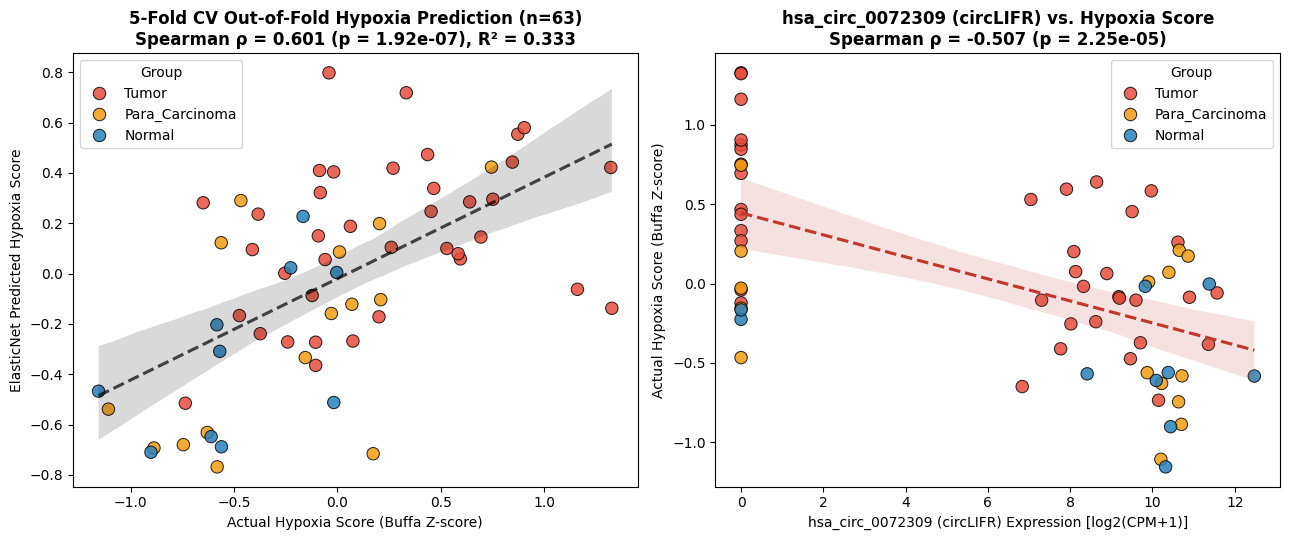

In [ ]:
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import time


# 1. Helper to query Ensembl REST API (GRCh38) for host gene symbol from "chrX:start|end"
CACHE_FILE = PROCESSED_DIR / "coord_to_gene_cache.json"

# Load existing local cache if available
if CACHE_FILE.exists():
    with open(CACHE_FILE, "r") as f:
        gene_cache = json.load(f)
else:
    gene_cache = {}

session = requests.Session()
session.headers.update({"Content-Type": "application/json", "User-Agent": "circDriver-Mapper/1.0"})

def map_coords_to_gene(coord_str, max_retries=4):
    # Return cached gene immediately if already resolved
    if coord_str in gene_cache and gene_cache[coord_str] != "Unknown":
        return gene_cache[coord_str]
    
    chrom, pos = coord_str.split(":")
    chrom = chrom.replace("chr", "")
    start, end = pos.split("|")
    url = f"https://rest.ensembl.org/overlap/region/human/{chrom}:{start}-{end}?feature=gene"
    
    for attempt in range(max_retries):
        try:
            r = session.get(url, timeout=10)
            if r.status_code == 200:
                data = r.json()
                genes = [g.get("external_name") for g in data if g.get("external_name")]
                result = ",".join(dict.fromkeys(genes)) if genes else "Intergenic"
                gene_cache[coord_str] = result
                time.sleep(0.15)  # Polite 150ms pacing to avoid Ensembl rate limit
                return result
            elif r.status_code == 429:
                # Ensembl rate-limit header tells us how many seconds to wait
                wait_sec = float(r.headers.get("Retry-After", 2.0))
                time.sleep(wait_sec)
            else:
                time.sleep(1.0)
        except requests.RequestException:
            time.sleep(1.5 * (attempt + 1))
    return "Unknown"

top15 = summary_circ.head(15).copy()
top15["Host_Gene"] = [map_coords_to_gene(idx) for idx in top15.index]
print("=== Top 15 Hypoxia-Linked circRNAs with Mapped Host Genes ===")
print(top15[["Host_Gene", "Selection_Freq", "Mean_Coef"]])
with open(CACHE_FILE, "w") as f:
    json.dump(gene_cache, f, indent=2)

print("=== Top 15 Hypoxia-Linked circRNAs (Cached & Rate-Limit Safe) ===")
print(top15[["Host_Gene", "Selection_Freq", "Mean_Coef"]])

# 2. Separate Positive (+) vs Negative (-) Candidate Drivers across all selected features
pos_drivers = summary_circ[summary_circ["Mean_Coef"] > 0].copy()
if not pos_drivers.empty:
    pos_drivers["Host_Gene"] = [map_coords_to_gene(idx) for idx in pos_drivers.head(10).index]
    print("\n=== Top Positive (+) Candidate Drivers (Upregulated in Hypoxia) ===")
    print(pos_drivers.head(10)[["Host_Gene", "Selection_Freq", "Mean_Coef"]])
else:
    print("\nNote: All top 50 f_regression features across the 63 samples were negatively correlated with hypoxia.")
    # Quickly compute direct Spearman rank correlation across the 38 Tumor samples to spot positive drivers
    tumor_only_ids = scores_df[scores_df["Group"] == "Tumor"].index
    y_tum = scores_df.loc[tumor_only_ids, "Hypoxia_Buffa"]
    X_tum = valid_circs[tumor_only_ids]
    
    corrs = X_tum.apply(lambda row: spearmanr(row, y_tum)[0], axis=1)
    top_pos_tum = corrs.nlargest(10).to_frame(name="Tumor_Spearman_rho")
    top_pos_tum["Host_Gene"] = [map_coords_to_gene(idx) for idx in top_pos_tum.index]
    print("\n=== Top 10 Positively Correlated circRNAs Inside Bladder Tumors (n=38, Spearman rho) ===")
    print(top_pos_tum.round(3))

# 3. Publication Figure: Out-of-Fold Predictions & Top Driver Expression
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel A: Out-of-Fold Predicted vs Actual Hypoxia Score
palette = {"Tumor": "#e74c3c", "Para_Carcinoma": "#f39c12", "Normal": "#2980b9"}
sns.scatterplot(
    data=eval_df, x="Actual_Hypoxia", y="Predicted_Hypoxia",
    hue="Group", palette=palette, s=80, alpha=0.85, edgecolor="k", ax=axes[0]
)
sns.regplot(
    data=eval_df, x="Actual_Hypoxia", y="Predicted_Hypoxia",
    scatter=False, color="black", line_kws={"linestyle": "--", "alpha": 0.7}, ax=axes[0]
)
axes[0].set_title(f"5-Fold CV Out-of-Fold Hypoxia Prediction (n=63)\nSpearman ρ = {r_s:.3f} (p = {p_s:.2e}), R² = {r2:.3f}", fontweight="bold")
axes[0].set_xlabel("Actual Hypoxia Score (Buffa Z-score)")
axes[0].set_ylabel("ElasticNet Predicted Hypoxia Score")

# Panel B: Top Candidate circLIFR (chr5:38523419|38530666) vs Hypoxia Score
top_circ_id = "chr5:38523419|38530666"
eval_df["circLIFR_log2CPM"] = X_circ_logcpm.loc[top_circ_id, eval_df.index]
sns.scatterplot(
    data=eval_df, x="circLIFR_log2CPM", y="Actual_Hypoxia",
    hue="Group", palette=palette, s=80, alpha=0.85, edgecolor="k", ax=axes[1]
)
sns.regplot(
    data=eval_df, x="circLIFR_log2CPM", y="Actual_Hypoxia",
    scatter=False, color="#c0392b", line_kws={"linestyle": "--"}, ax=axes[1]
)
rho_lifr, p_lifr = spearmanr(eval_df["circLIFR_log2CPM"], eval_df["Actual_Hypoxia"])
axes[1].set_title(f"hsa_circ_0072309 (circLIFR) vs. Hypoxia Score\nSpearman ρ = {rho_lifr:.3f} (p = {p_lifr:.2e})", fontweight="bold")
axes[1].set_xlabel("hsa_circ_0072309 (circLIFR) Expression [log2(CPM+1)]")
axes[1].set_ylabel("Actual Hypoxia Score (Buffa Z-score)")

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "GSE236932_Hypoxia_ElasticNet_Results.png", dpi=300)
plt.show()

In [5]:
top15

,Selection_Freq,Mean_Coef,Abs_Mean_Coef,Host_Gene
circRNA_id,,,,
chr18:6213149|6312056,1.0,-0.079327,0.079327,"L3MBTL4-AS1,L3MBTL4"
chr5:38523419|38530666,0.8,-0.085717,0.085717,Unknown
chr5:122801869|122803613,0.8,-0.021312,0.021312,Unknown
chr7:92457552|92492286,0.6,-0.042744,0.042744,Unknown
chr4:120754553|120811449,0.6,-0.025198,0.025198,Unknown
chr16:3536122|3536994,0.6,-0.011868,0.011868,Unknown
chr8:96834973|96880005,0.6,-0.011759,0.011759,CPQ
chr9:4286038|4286523,0.6,-0.007114,0.007114,Unknown
chr9:111527268|111534353,0.4,-0.028928,0.028928,ZNF483


In [3]:
top15

,Selection_Freq,Mean_Coef,Abs_Mean_Coef,Host_Gene
circRNA_id,,,,
chr18:6213149|6312056,1.0,-0.079327,0.079327,"L3MBTL4-AS1,L3MBTL4"
chr5:38523419|38530666,0.8,-0.085717,0.085717,LIFR
chr5:122801869|122803613,0.8,-0.021312,0.021312,SNX2
chr7:92457552|92492286,0.6,-0.042744,0.042744,"ERVW-1,GATAD1,PEX1"
chr4:120754553|120811449,0.6,-0.025198,0.025198,"RNU6-550P,PRDM5"
chr16:3536122|3536994,0.6,-0.011868,0.011868,CLUAP1
chr8:96834973|96880005,0.6,-0.011759,0.011759,CPQ
chr9:4286038|4286523,0.6,-0.007114,0.007114,GLIS3
chr9:111527268|111534353,0.4,-0.028928,0.028928,ZNF483
